### Lab Assignment – Clustering of Credit Card Customer Data

### 1. Scatterplot of `Avg_Credit_Limit` and `Total_Credit_Cards`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('CC_Customer_Dataset.csv')

df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

In [3]:
X = df.drop(columns=['Sl_No', 'Customer Key'])

X.describe()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000
mean,34574.242424,4.706061,2.403030,2.606061,3.583333
std,37625.487804,2.167835,1.631813,2.935724,2.865317
min,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,48000.000000,6.000000,4.000000,4.000000,5.000000
max,200000.000000,10.000000,5.000000,15.000000,10.000000


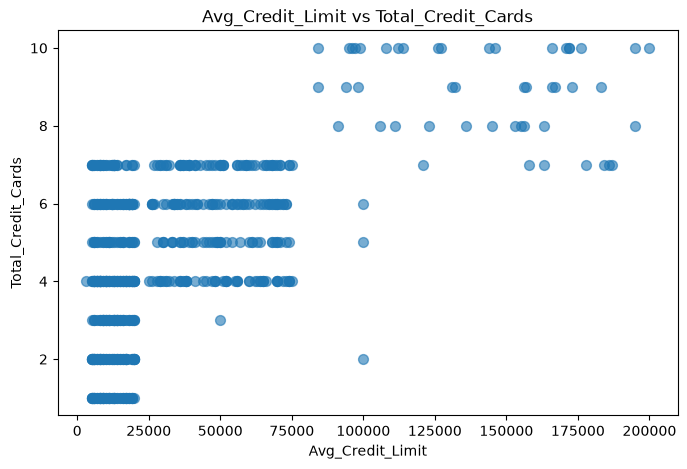

Correlation: 0.6089


In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(X['Avg_Credit_Limit'], X['Total_Credit_Cards'], s=50, alpha=0.6)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

corr = X['Avg_Credit_Limit'].corr(X['Total_Credit_Cards'])

print(f'Correlation: {corr:.4f}')

**Answer (Question 1):** The distribution is **not linear**. The Pearson correlation between `Avg_Credit_Limit` and `Total_Credit_Cards` is only 0.61, a moderate positive relationship, and the points do not follow a single straight line. Instead they form step-like blocks: customers with a low limit (up to about 20000) have 1 to 4 cards, customers with a medium limit (about 25000 to 75000) have 4 to 7 cards, and a small, widely spread group with a high limit (above about 85000) has 7 to 10 cards. `Total_Credit_Cards` is a discrete count, so the points also stack in horizontal bands. A straight line would not describe these blocks well.

### 2. K-Means and the Elbow Method

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

sse = []
sil = []

K = range(1, 11)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)

    sse.append(km.inertia_)

    if k > 1:
        sil.append(silhouette_score(X_scaled, km.labels_))
    else:
        sil.append(0)

    print(f'k = {k}, SSE: {km.inertia_:.2f}, silhouette: {sil[-1]:.4f}')

d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

k = 1, SSE: 3300.00, silhouette: 0.0000
k = 2, SSE: 2040.99, silhouette: 0.4184
k = 3, SSE: 933.04, silhouette: 0.5157
k = 4, SSE: 780.77, silhouette: 0.3557
k = 5, SSE: 704.48, silhouette: 0.2717
k = 6, SSE: 642.27, silhouette: 0.2560
k = 7, SSE: 599.93, silhouette: 0.2482
k = 8, SSE: 567.33, silhouette: 0.2271


d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

k = 9, SSE: 542.25, silhouette: 0.2141
k = 10, SSE: 516.24, silhouette: 0.2137


d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


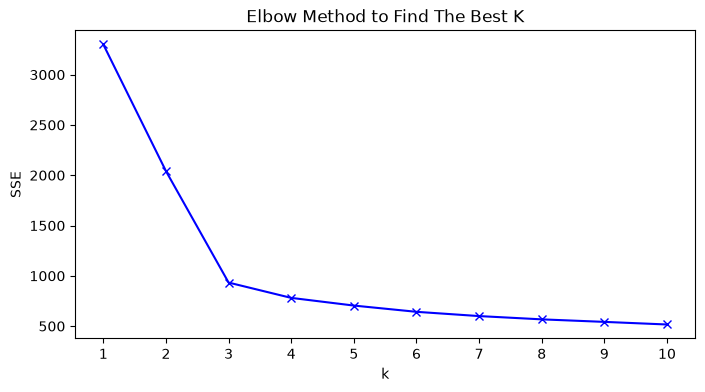

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method to Find The Best K')
plt.xticks(list(K))
plt.show()

**Answer (Question 2):** The features were standardized first, because `Avg_Credit_Limit` (up to 200000) would otherwise dominate the distance calculation, and all five usable variables were used (`Sl_No` and `Customer Key` are identifiers and were dropped). The SSE falls from 3300 (k=1) to 2041 (k=2) and 933 (k=3), which are drops of 38% and 54%. From k=3 to k=4 it only falls by 16% more, and the curve is almost flat afterwards, so the elbow is at **k = 3**. The silhouette score supports this: it is the highest at k=3 (0.516) and drops to 0.356 at k=4. Choosing a larger k would only split existing groups into smaller ones without adding a clear new segment.

### 3. K-Means Clustering Result

d:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


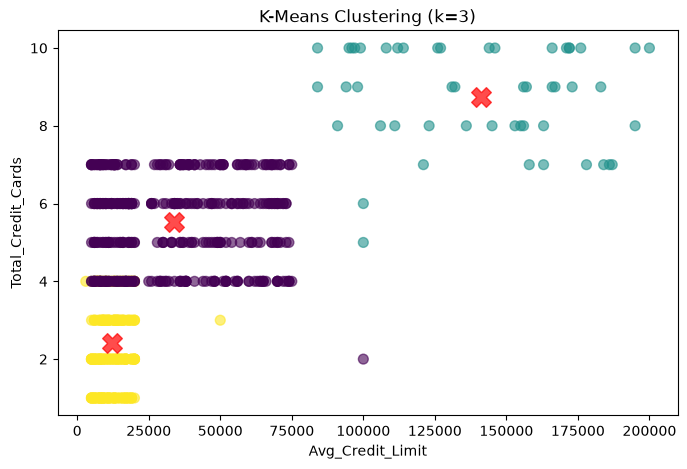

In [7]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

labels_km = kmeans.fit_predict(X_scaled)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 5))
plt.scatter(X['Avg_Credit_Limit'], X['Total_Credit_Cards'], c=labels_km, s=50, alpha=0.6, cmap='viridis')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.7, marker='X')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('K-Means Clustering (k=3)')
plt.show()

In [8]:
profile = X.assign(Cluster=labels_km).groupby('Cluster').mean().round(2)
counts = pd.Series(labels_km).value_counts().sort_index()

profile['Customers'] = counts

profile

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customers
Cluster,,,,,,
0,33782.38,5.52,3.49,0.98,2.00,386
1,141040.00,8.74,0.60,10.90,1.08,50
2,12174.11,2.41,0.93,3.55,6.87,224


**Answer (Question 3):** The scatter plot shows three customer segments. Cluster 1 (50 customers) has the highest credit limit (about 141040), the most credit cards (8.7) and mainly uses online visits (10.9) with few calls. Cluster 2 (224 customers) has the lowest credit limit (about 12174), only 2.4 cards on average and makes the most calls to the bank (6.9). Cluster 0 (386 customers) sits in the middle with a limit of about 33782 and visits the bank in person more than the other groups (3.5 visits) while rarely using the online channel (1.0 visits). Note that the plot only shows two of the five variables, so the groups overlap a little in this view even though they are separated in the full feature space.

### 4. DBSCAN with All Usable Variables

In [9]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

min_samples = 2 * X.shape[1]

print(f'min_samples: {min_samples}')

min_samples: 10


### 5. Elbow Method for DBSCAN (k-distance graph)

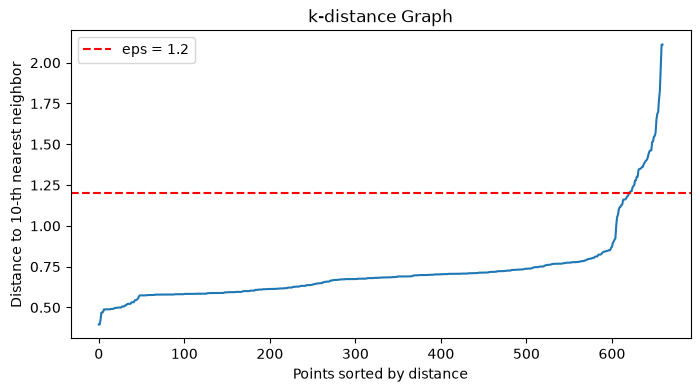

In [10]:
nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_scaled)

distances, _ = nn.kneighbors(X_scaled)

k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.axhline(y=1.2, color='red', linestyle='--', label='eps = 1.2')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'Distance to {min_samples}-th nearest neighbor')
plt.title('k-distance Graph')
plt.legend()
plt.show()

In [11]:
for eps in [0.8, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.8]:
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)

    n_cl = len(set(lab)) - (1 if -1 in lab else 0)

    print(f'eps = {eps}, clusters: {n_cl}, noise: {(lab == -1).sum()}')

eps = 0.8, clusters: 1, noise: 54
eps = 1.0, clusters: 1, noise: 53
eps = 1.1, clusters: 3, noise: 33
eps = 1.2, clusters: 2, noise: 13
eps = 1.3, clusters: 2, noise: 9
eps = 1.4, clusters: 2, noise: 3
eps = 1.5, clusters: 2, noise: 3
eps = 1.8, clusters: 1, noise: 1


**Answer (Question 5):** DBSCAN has no `k` parameter. The closest equivalent of the elbow method is the k-distance graph: each point's distance to its `min_samples`-th nearest neighbor (10, which is 2 x the number of features) is sorted and plotted, and the elbow gives `eps`. The curve is almost flat up to a distance of about 0.9 and then climbs sharply, which means the points after the bend are sparse outliers. Several `eps` values after the bend (1.2 to 1.5) give a stable result of two clusters, so `eps = 1.2` was chosen: it is large enough to keep the dense customers together and small enough to leave the clear outliers as noise. `eps` below about 1.0 leaves only one cluster with more than 50 noise points, and a large `eps` such as 1.8 merges everything into one cluster.

### 6. Silhouette Score and DBI of the DBSCAN Model

In [12]:
eps = 1.2

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels_db = dbscan.fit_predict(X_scaled)

n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = (labels_db == -1).sum()

print(f'Number of clusters: {n_clusters}')
print(f'Number of noise points: {n_noise}')
print(pd.Series(labels_db).value_counts().sort_index())

Number of clusters: 2
Number of noise points: 13
-1     13
 0    608
 1     39
Name: count, dtype: int64


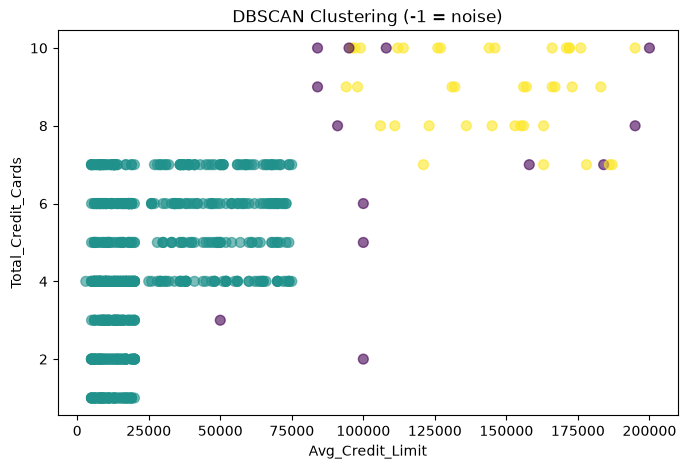

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(X['Avg_Credit_Limit'], X['Total_Credit_Cards'], c=labels_db, s=50, alpha=0.6, cmap='viridis')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('DBSCAN Clustering (-1 = noise)')
plt.show()

In [14]:
mask = labels_db != -1

sil_db = silhouette_score(X_scaled[mask], labels_db[mask])
dbi_db = davies_bouldin_score(X_scaled[mask], labels_db[mask])

sil_km = silhouette_score(X_scaled, labels_km)
dbi_km = davies_bouldin_score(X_scaled, labels_km)

results = pd.DataFrame({
    'Model': ['K-Means (k=3)', 'DBSCAN'],
    'Silhouette Score': [sil_km, sil_db],
    'Davies-Bouldin Index': [dbi_km, dbi_db]
})

print(f'DBSCAN silhouette score: {sil_db}')
print(f'DBSCAN Davies-Bouldin Index: {dbi_db}')

results

DBSCAN silhouette score: 0.5685985141804305
DBSCAN Davies-Bouldin Index: 0.6073750936839484


,Model,Silhouette Score,Davies-Bouldin Index
0,K-Means (k=3),0.515718,0.679699
1,DBSCAN,0.568599,0.607375


In [15]:
ct = pd.crosstab(labels_km, labels_db, rownames=['K-Means'], colnames=['DBSCAN'])

ct

DBSCAN,-1,0,1
K-Means,,,
0,1,385,0
1,11,0,39
2,1,223,0


**Answer (Question 6):** With `eps = 1.2` and `min_samples = 10`, DBSCAN found 2 clusters and labeled 13 customers (2.0%) as noise. Computed on the clustered points only (noise excluded), the silhouette score is 0.5686 and the Davies-Bouldin Index is 0.6074. For comparison, K-Means with k=3 gets a silhouette score of 0.5157 and a DBI of 0.6797. DBSCAN scores slightly better on both metrics, but the comparison is not completely fair because DBSCAN ignores its noise points. The cross-tabulation shows that DBSCAN merged the two K-Means groups with low and middle credit limits into one large cluster (608 customers) and only separated the high-limit group (39 customers); 11 of its 13 noise points also come from that high-limit group. So DBSCAN is good at isolating the unusual high-limit customers, while K-Means with k=3 gives the more useful segmentation of the whole customer base.